# Exploration ETL depuis MinIO (France Travail + WTTJ)

Objectif: lire les 2 sources brutes depuis MinIO, normaliser avec pandas, fusionner et produire une source finale unique.

## 1) Imports essentiels

Librairies nécessaires pour MinIO, pandas et la manipulation JSON.

In [62]:
from __future__ import annotations

import io
import json
import os
from pathlib import Path

import pandas as pd
from minio import Minio


## 2) Chargement de la configuration (.env)

On charge les variables sensibles sans les écrire en dur dans le notebook.

In [63]:
def load_dotenv_file(path: str = '.env') -> None:
    env_path = Path(path)
    if not env_path.exists():
        return

    for raw_line in env_path.read_text(encoding='utf-8').splitlines():
        line = raw_line.strip()
        if not line or line.startswith('#') or '=' not in line:
            continue

        key, value = line.split('=', 1)
        key = key.strip()
        value = value.strip()
        if not key:
            continue

        if (value.startswith('\"') and value.endswith('\"')) or (value.startswith("'") and value.endswith("'")):
            value = value[1:-1]

        os.environ.setdefault(key, value)


load_dotenv_file()
print('dotenv loaded')

dotenv loaded


## 3) Connexion MinIO

Connexion au Data Lake (buckets raw-api et raw-scrap).

In [64]:
endpoint = os.environ.get('MINIO_ENDPOINT', 'localhost:9000').strip()
access_key = os.environ['MINIO_ROOT_USER']
secret_key = os.environ['MINIO_ROOT_PASSWORD']
secure = os.environ.get('MINIO_SECURE', 'false').strip().lower() in {'1', 'true', 'yes', 'on'}

bucket_api = os.environ.get('MINIO_BUCKET_RAW_API', 'raw-api')
bucket_scrap = os.environ.get('MINIO_BUCKET_RAW_SCRAP', 'raw-scrap')

client = Minio(endpoint=endpoint, access_key=access_key, secret_key=secret_key, secure=secure)
print('MinIO client ready:', endpoint, '| secure=', secure)

MinIO client ready: localhost:9000 | secure= False


## 4) Fonctions utilitaires MinIO

Fonctions simples pour lire le dernier objet disponible par source.

In [65]:
def latest_object_name(bucket: str, prefix: str) -> str:
    objs = list(client.list_objects(bucket_name=bucket, prefix=prefix, recursive=True))
    if not objs:
        raise RuntimeError(f'Aucun objet trouve dans {bucket}/{prefix}')
    latest = sorted(objs, key=lambda o: o.last_modified or 0)[-1]
    return latest.object_name


def read_json_from_minio(bucket: str, object_name: str) -> dict:
    resp = client.get_object(bucket_name=bucket, object_name=object_name)
    try:
        payload_bytes = resp.read()
    finally:
        resp.close()
        resp.release_conn()
    return json.loads(payload_bytes.decode('utf-8'))


## 5) Extraction des 2 sources brutes

On récupère le dernier JSON France Travail et le dernier JSON WTTJ.

In [66]:
ft_object = latest_object_name(bucket_api, 'france_travail/')
wttj_object = latest_object_name(bucket_scrap, 'welcome_to_the_jungle/')

ft_payload = read_json_from_minio(bucket_api, ft_object)
wttj_payload = read_json_from_minio(bucket_scrap, wttj_object)

print('France Travail object:', ft_object, '| offers:', len(ft_payload.get('offers', [])))
print('WTTJ object:', wttj_object, '| offers:', len(wttj_payload.get('offers', [])))

France Travail object: france_travail/2026/05/18/offers_20260518T090005Z.json | offers: 150
WTTJ object: welcome_to_the_jungle/2026/05/18/offers_20260518T090003Z.json | offers: 0


## 6) Règles de nettoyage/normalisation

On crée un schéma commun pour aligner les 2 formats.

In [67]:
def clean_text(v):
    if v is None:
        return None
    s = str(v).strip()
    return s or None


def alternance_flag_from_offer(offer: dict) -> bool:
    value = offer.get('alternance')
    return value if isinstance(value, bool) else False


def normalize_france_travail(offer: dict) -> dict:
    contract_type_raw = clean_text(offer.get('typeContrat'))
    title = clean_text(offer.get('intitule'))
    alternance_flag = alternance_flag_from_offer(offer)

    salary = offer.get('salaire')
    salary_label = clean_text(salary.get('libelle')) if isinstance(salary, dict) else clean_text(salary)

    return {
        'source': 'france_travail',
        'source_offer_id': clean_text(offer.get('id')),
        'external_url': clean_text((offer.get('origineOffre') or {}).get('urlOrigine')),
        'title': title,
        'company_name': clean_text((offer.get('entreprise') or {}).get('nom')),
        'city': clean_text((offer.get('lieuTravail') or {}).get('commune')),
        'postal_code': clean_text((offer.get('lieuTravail') or {}).get('codePostal')),
        'contract_type_raw': contract_type_raw,
        'contract_type': contract_type_raw,
        'alternance': alternance_flag,
        'description': clean_text(offer.get('description')),
        'salary_label': salary_label,
        'salary_min': None,
        'salary_max': None,
        'salary_currency': None,
        'experience_required': clean_text(offer.get('experienceExige')),
        'education_level': clean_text(offer.get('niveauFormationLibelle')),
        'created_at': clean_text(offer.get('dateCreation')),
    }


def normalize_wttj(offer: dict) -> dict:
    contract_type_raw = clean_text(offer.get('typeContrat'))
    title = clean_text(offer.get('intitule'))
    alternance_flag = alternance_flag_from_offer(offer)

    salaire = offer.get('salaire') if isinstance(offer.get('salaire'), dict) else {}

    return {
        'source': 'welcome_to_the_jungle',
        'source_offer_id': clean_text(offer.get('id')),
        'external_url': clean_text((offer.get('origineOffre') or {}).get('urlOrigine')),
        'title': title,
        'company_name': clean_text((offer.get('entreprise') or {}).get('nom')),
        'city': clean_text((offer.get('lieuTravail') or {}).get('commune')),
        'postal_code': clean_text((offer.get('lieuTravail') or {}).get('codePostal')),
        'contract_type_raw': contract_type_raw,
        'contract_type': contract_type_raw,
        'alternance': alternance_flag,
        'description': clean_text(offer.get('description')),
        'salary_label': clean_text(salaire.get('libelle')),
        'salary_min': salaire.get('min') if isinstance(salaire.get('min'), (int, float)) else None,
        'salary_max': salaire.get('max') if isinstance(salaire.get('max'), (int, float)) else None,
        'salary_currency': clean_text(salaire.get('devise')),
        'experience_required': clean_text(offer.get('experienceRequise')),
        'education_level': clean_text(offer.get('niveauEtude')),
        'created_at': clean_text(offer.get('dateCreation')),
    }


## 7) Fusion + dédoublonnage

Concaténation des DataFrames puis suppression des doublons.

In [68]:
ft_rows = [normalize_france_travail(o) for o in ft_payload.get('offers', []) if isinstance(o, dict)]
wttj_rows = [normalize_wttj(o) for o in wttj_payload.get('offers', []) if isinstance(o, dict)]

df_ft = pd.DataFrame(ft_rows)
df_wttj = pd.DataFrame(wttj_rows)

df_unified = pd.concat([df_ft, df_wttj], ignore_index=True)
df_unified = df_unified.drop_duplicates(subset=['source', 'source_offer_id', 'external_url'], keep='last')

print('France Travail rows:', len(df_ft))
print('WTTJ rows:', len(df_wttj))
print('Unified rows:', len(df_unified))
df_unified.head(5)

France Travail rows: 150
WTTJ rows: 0
Unified rows: 150


,source,source_offer_id,external_url,title,company_name,city,postal_code,contract_type_raw,contract_type,alternance,description,salary_label,salary_min,salary_max,salary_currency,experience_required,education_level,created_at
0,france_travail,208JMBX,https://candidat.francetravail.fr/offres/reche...,Aide jardinier / Aide jardinière (H/F),AXEO SERVICES,52121,52000,CDD,CDD,False,Vous ferez le nettoyage extérieur dans des éco...,Horaire de 12.02 Euros sur 12 mois,None,None,None,E,None,2026-05-18T10:59:56.251Z
1,france_travail,208JMBW,https://candidat.francetravail.fr/offres/reche...,Employé (e) de ménage H/F CDI Perpignan,TOMEFE SERVICES,66050,66530,CDI,CDI,False,"¡ Vous avez le talent, nous avons les clients ...",Mensuel de 1970.0 Euros à 2000.0 Euros sur 12....,None,None,None,D,None,2026-05-18T10:59:56.073Z
2,france_travail,208JMBV,https://candidat.francetravail.fr/offres/reche...,Opérateur monteur (H/F),RAS 1170,14225,14160,MIS,MIS,False,Vous avez envie de diversifier vos expériences...,Horaire de 12.02 Euros sur 12.0 mois,None,None,None,D,None,2026-05-18T10:59:48.766Z
3,france_travail,208JMBT,https://candidat.francetravail.fr/offres/reche...,Chargé d'affaires CVC (H/F),TRAVAIL TEMPORAIRE TECHNIQUE,78688,78960,CDI,CDI,False,"TTT SAS, agence d'emploi à taille humaine spéc...",Annuel de 42000.0 Euros à 48000.0 Euros sur 12...,None,None,None,E,None,2026-05-18T10:59:48.272Z
4,france_travail,208JMBS,https://candidat.francetravail.fr/offres/reche...,Hôte / Hôtesse de caisse (H/F),INTERMARCHE,62528,62750,CDD,CDD,False,Votre Intermarché Loos-en-Gohelle recrute un.e...,Horaire de 12.05 Euros sur 12.0 mois,None,None,None,E,None,2026-05-18T10:59:47.356Z


## 8) Contrôles de qualité

Vérifications utiles: taux de null, distribution des contrats, volume par source.

In [69]:
print('Columns:', list(df_unified.columns))
print('\nNull ratio by column:')
display((df_unified.isna().mean().sort_values(ascending=False) * 100).round(2).to_frame('null_pct'))

print('\nContract distribution (top 15):')
display(df_unified['contract_type'].fillna('NONE').value_counts().head(15).to_frame('count'))

print('\nRows by source:')
display(df_unified['source'].value_counts().to_frame('count'))

Columns: ['source', 'source_offer_id', 'external_url', 'title', 'company_name', 'city', 'postal_code', 'contract_type_raw', 'contract_type', 'alternance', 'description', 'salary_label', 'salary_min', 'salary_max', 'salary_currency', 'experience_required', 'education_level', 'created_at']

Null ratio by column:


,null_pct
education_level,100.00
salary_currency,100.00
salary_max,100.00
salary_min,100.00
salary_label,25.33
company_name,6.67
city,1.33
postal_code,1.33
source,0.00
experience_required,0.00



Contract distribution (top 15):


,count
contract_type,
CDI,73
CDD,37
MIS,30
SAI,8
DIN,1
TTI,1



Rows by source:


,count
source,
france_travail,150


## 9) Export de la source finale

Sauvegarde du dataset final en CSV et JSON pour la suite ETL/Postgres.

In [70]:
out_dir = Path('data/processed')
out_dir.mkdir(parents=True, exist_ok=True)

csv_path = out_dir / 'unified_offers_from_minio.csv'
json_path = out_dir / 'unified_offers_from_minio.json'

df_unified.to_csv(csv_path, index=False)
df_unified.to_json(json_path, orient='records', force_ascii=False, indent=2)

print('Saved:', csv_path)
print('Saved:', json_path)

Saved: data/processed/unified_offers_from_minio.csv
Saved: data/processed/unified_offers_from_minio.json


## 10) Exploration Visuelle avec Seaborn

Génération de graphiques statistiques pour analyser les tendances du marché de l'emploi en Python.

In [71]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="pastel")

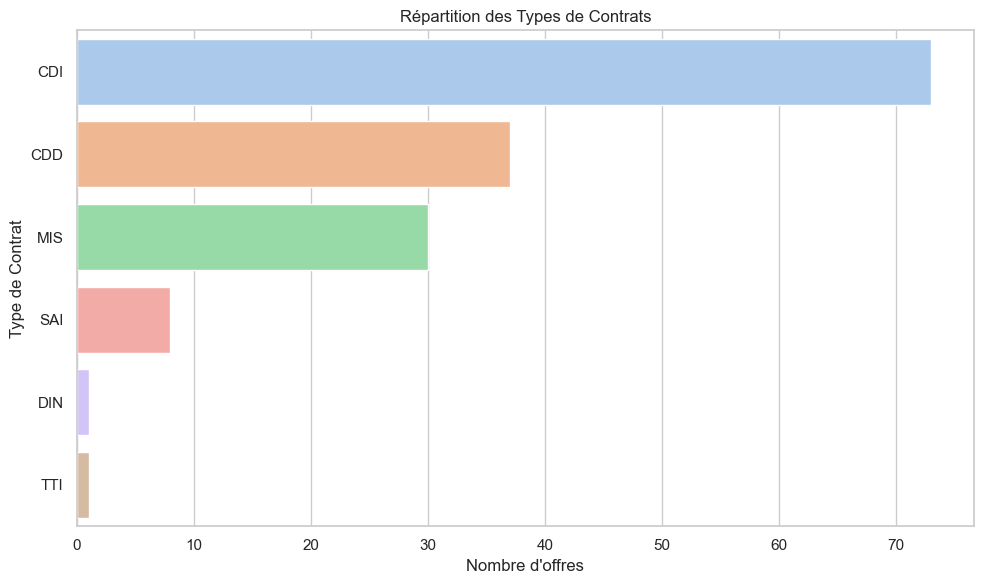

In [75]:
plt.figure(figsize=(10, 6))
contract_counts = df_unified['contract_type'].fillna('Non spécifié').value_counts()
sns.barplot(x=contract_counts.values, y=contract_counts.index, hue=contract_counts.index, legend=False)
plt.title('Répartition des Types de Contrats')
plt.xlabel("Nombre d'offres")
plt.ylabel('Type de Contrat')
plt.tight_layout()
plt.show()

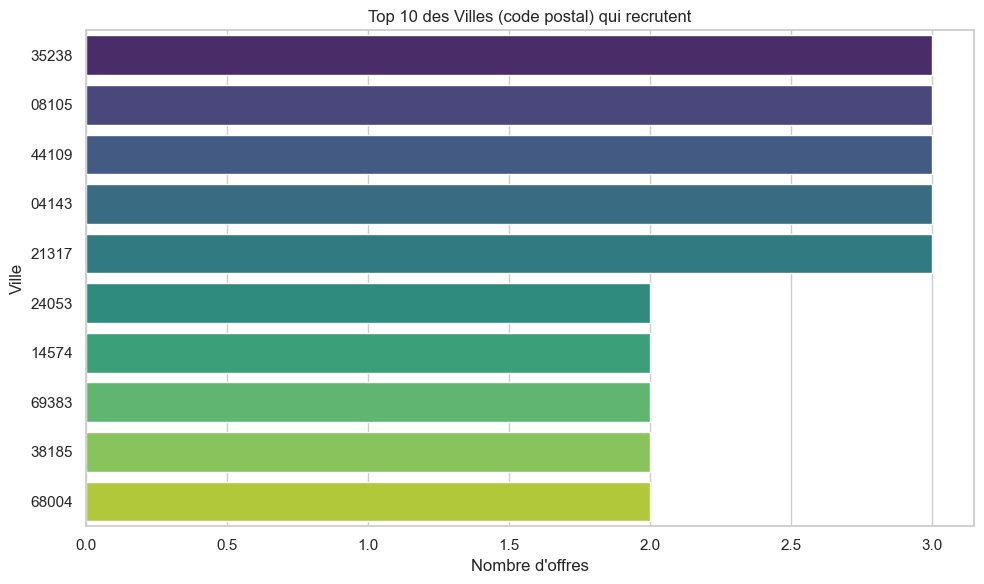

In [76]:
plt.figure(figsize=(10, 6))
top_cities = df_unified['city'].value_counts().head(10)
sns.barplot(x=top_cities.values, y=top_cities.index, hue=top_cities.index, legend=False, palette="viridis")
plt.title('Top 10 des Villes (code postal) qui recrutent')
plt.xlabel("Nombre d'offres")
plt.ylabel('Ville')
plt.tight_layout()
plt.show()